# BFMNs from association and valence task

In [1]:
import os
import sys
import pandas as pd

# Add project root (parent of this scripts/ folder) to sys.path once
PROJECT_ROOT = os.path.abspath("..")
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

# Now import from ../src folder
from src.models_and_vars import load_env_vars, ensure_nltk_path, init_spacy_and_emo
from src.valence import fmn_valence_stats, categorize_valence_multiple, plot_valence_distribution
from src.fmtools import (
    monitor_memory,
    draw_fmnts,
    make_emo_flowers,
    extract_bfmn_structural_features,
    all_fmns_features_df,
    verify_and_report_nodes,
    inspect_fmn
)
from src.io import export_df, export_whole_fmn_multiple_custom, import_fmnt_from_old_text_format
from src.data_processing import (
    subset_by_group_labels,
    build_association_df,
    filter_associations_by_occurrences,
)

pd.set_option('display.max_rows', 100)

In [2]:
# you do not need to run these download commands every time. nltk.download()
# saves these data packages to your local file system in the nltk_data directory.
# Once they are downloaded, they are available for NLTK to use in any session.

'''nltk.download('wordnet')
nltk.download('omw-1.4') # for italian and multilingual support, if needed
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng') # for word tokenization
nltk.download('averaged_perceptron_tagger') # for POS tagging
'''


"nltk.download('wordnet')\nnltk.download('omw-1.4') # for italian and multilingual support, if needed\nnltk.download('punkt')\nnltk.download('punkt_tab')\nnltk.download('averaged_perceptron_tagger_eng') # for word tokenization\nnltk.download('averaged_perceptron_tagger') # for POS tagging\n"

# Environment and models settings

In [3]:
# Set language once; everything else adapts
language = "italian"  # or "english"
env_file_path = "../env"

# Execute setup
load_env_vars(env_file_path, language=language)
ensure_nltk_path()

nlp, emo = init_spacy_and_emo(language)

# Also preload both models for explicit use
nlp_en, _ = init_spacy_and_emo("english")
nlp_it, _ = init_spacy_and_emo("italian")

Loaded SPACY_MODEL_PATH_EN: /home/franaz/coding/spacy-models/en_core_web_lg/en_core_web_lg-3.8.0
Loaded SPACY_MODEL_PATH_IT: /home/franaz/coding/spacy-models/it_core_news_lg/it_core_news_lg-3.7.0
Loaded NLTK_DATA: /home/franaz/nltk_data



/home/franaz/coding/python/projects/data_science/networks/rassereno/.rassereno-py310/lib/python3.10/site-packages/spacy/util.py:922: UserWarning: [W095] Model 'it_core_news_lg' (3.7.0) was trained with spaCy v3.7.0 and may not be 100% compatible with the current version (3.8.7). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


# fmn and paths settings

In [4]:
# Dynamic output paths system for pipelines
base_output_path = '../out'
project_name = 'merged'
formatted_data_dir = 'formatting'
use_prelemmatized_brysbaert = True # A lot faster (highly suggested, but needs pre-lemmatized data)
# Set the type of fmn to use: 'bfmns' or 'tfmns'
# (this is used for the folder name, not for the file names)
fmn_type = 'bfmns'
# Keywords that we want to check for in the textual data. If not empty,
# semantic frame plots will be created for these keywords. Otherwise,
# the full FMNs will be visualized.
keywords = []
keywords = ['matematica','ansia','stress','depressione','statistica','informatica','fisica','scienza','prestazione','esame','voto','valutazione','scuola','competizione','università']
# Lemmatization setting
lemmatize = False

# Types of output: aggregated and individual (entire dataset vs per participant FMNs)
# Choose any subset: {'aggregated'}, {'individual'}, or both
# How to use:
# Only aggregated: methods = {'aggregated'}
# Only individual: methods = {'individual'}
# Both: methods = {'aggregated', 'individual'}
ALLOWED_METHODS = {'aggregated', 'individual'}
methods = {'aggregated'}
methods = {m.strip().lower() for m in (methods if isinstance(methods, (list, set, tuple)) else [methods])}
methods = methods & ALLOWED_METHODS
if not methods:
    raise ValueError("No valid methods selected. Use 'aggregated' and/or 'individual'.")

# Groups to subset the data (if needed). Use labels and .startswith() condition
# from the 'participant_id' column to create groups.
group_name = 'highschool_south_filtered'  # fmn name when using groups
if group_name:
    fmn_type = f'{group_name}_{fmn_type}'

# If dfs_and_group_labels is longer than 1, merge the data from the different paths.
dfs_and_group_labels = []
df1 = pd.read_csv('../out/formatting/splitted_dfs/high_anxiety_high_school_gpt_oss.csv')
dfs_and_group_labels = [
    (df1, None)   # list of (df, group_labels)
]

# print all unique participants
all_participants = set()
for df, group_labels in dfs_and_group_labels:
    all_participants.update(df['participant_id'].unique())
print(f"All unique participants across datasets: {len(all_participants)}")
print(f"Unique participants labels: {all_participants}\n")

# Resolve output directories
if methods == {'aggregated'}:
    files_output_dir = f'{base_output_path}/{project_name}/aggregated/{fmn_type}'
    data_output_dir = f'{base_output_path}/{project_name}/aggregated/{formatted_data_dir}/{fmn_type}'
if methods == {'individual'}:
    files_output_dir = f'{base_output_path}/{project_name}/individual/{fmn_type}'
    data_output_dir = f'{base_output_path}/{project_name}/individual/{formatted_data_dir}/{fmn_type}'

All unique participants across datasets: 28
Unique participants labels: {'gpt_oss_128', 'gpt_oss_223', 'gpt_oss_095', 'gpt_oss_131', 'gpt_oss_745', 'gpt_oss_305', 'gpt_oss_508', 'gpt_oss_195', 'gpt_oss_721', 'gpt_oss_949', 'gpt_oss_847', 'gpt_oss_540', 'gpt_oss_547', 'gpt_oss_882', 'gpt_oss_196', 'gpt_oss_579', 'gpt_oss_643', 'gpt_oss_748', 'gpt_oss_226', 'gpt_oss_253', 'gpt_oss_107', 'gpt_oss_439', 'gpt_oss_960', 'gpt_oss_269', 'gpt_oss_290', 'gpt_oss_972', 'gpt_oss_706', 'gpt_oss_126'}



### Data loading and pre-processing

[1] unique 'participant_id' before: 28 | after: 28 | removed: 0
[1] filtered rows from 'participant_id':
[total] unique 'participant_id' after subsetting and merging: 28

Top 50 association pairs (of 761 total):
     cue_word           word  pair_count
   cognizione        memoria          28
   psicologia  comportamento          28
       fisica        energia          28
  valutazione       feedback          26
    benessere         salute          26
  personalita      carattere          25
   statistica           dati          24
   matematica         logica          24
   creativita           arte          24
    terapeuta       supporto          24
   psicologia       emozioni          23
  informatica         codice          23
        ansia preoccupazione          23
  valutazione        analisi          22
  innovazione     tecnologia          22
  personalita       identita          22
   professore    ispirazione          22
 neuroscienze        neuroni          22
comportam

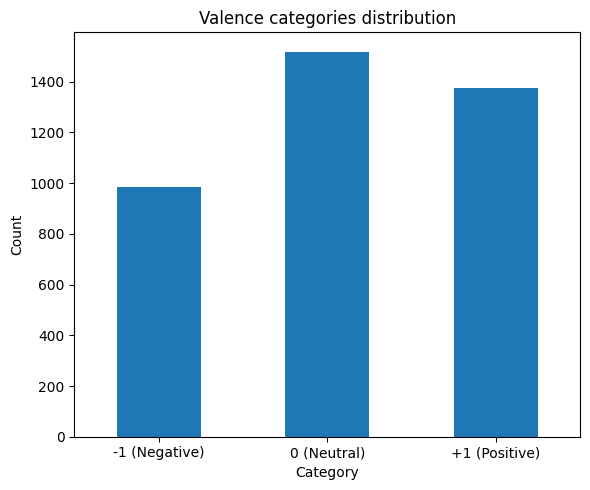

In [5]:
# Subset by group labels if multiple dataframes and labels provided, otherwise just merge):
wide_df = subset_by_group_labels(dfs_and_group_labels, col='participant_id')
long_df = build_association_df(wide_df, lemmatize=lemmatize, lang=language)

# Filter associations by minimum occurrences
min_association_occurrences = 2
# Remove the associations cue_word-word that do not occur more
# than min_association_occurrences times
long_df = filter_associations_by_occurrences(long_df, min_association_occurrences=min_association_occurrences)

final_df, custom_valences = categorize_valence_multiple(
    long_df,
    alpha=0.1,
    min_occurrences=3,
    return_custom_valences=True,
    direction_stat='mean'
)

# plot the valence distribution
plot_valence_distribution(final_df)

In [6]:
# Export long and categorized dataframes (edit path as needed)
# Also dynamically name files based if method is aggregated or individual
if len(dfs_and_group_labels) == 1:
    export_df(long_df, f'{base_output_path}/{data_output_dir}', filename=f'{group_name}_associations_valence_long')
    export_df(final_df, f'{base_output_path}/{data_output_dir}', filename=f'{group_name}_associations_valence_categorization')

elif len(dfs_and_group_labels) > 1:
    export_df(long_df, f'{base_output_path}/{data_output_dir}', filename=f'{group_name}_associations_valence_long_merged')
    export_df(final_df, f'{base_output_path}/{data_output_dir}', filename=f'{group_name}_associations_valence_categorization_merged')

File highschool_south_filtered_associations_valence_long.csv already exists in ../out/../out/merged/aggregated/formatting/highschool_south_filtered_bfmns. Use overwrite=True to replace it.
File highschool_south_filtered_associations_valence_categorization.csv already exists in ../out/../out/merged/aggregated/formatting/highschool_south_filtered_bfmns. Use overwrite=True to replace it.


## Run the pipeline on preprocessed data

### Aggregated pipeline

Starting pipeline...

Current memory usage: 4656.78 MB
[✔] Network exported to '../out/merged/aggregated/highschool_south_filtered_bfmns/highschool_south_filtered.txt'
Drawing 1 networks in batches of 5

Drawing batch 1/1
Current memory usage: 4656.78 MB
Drawing TFMN: highschool_south_filtered


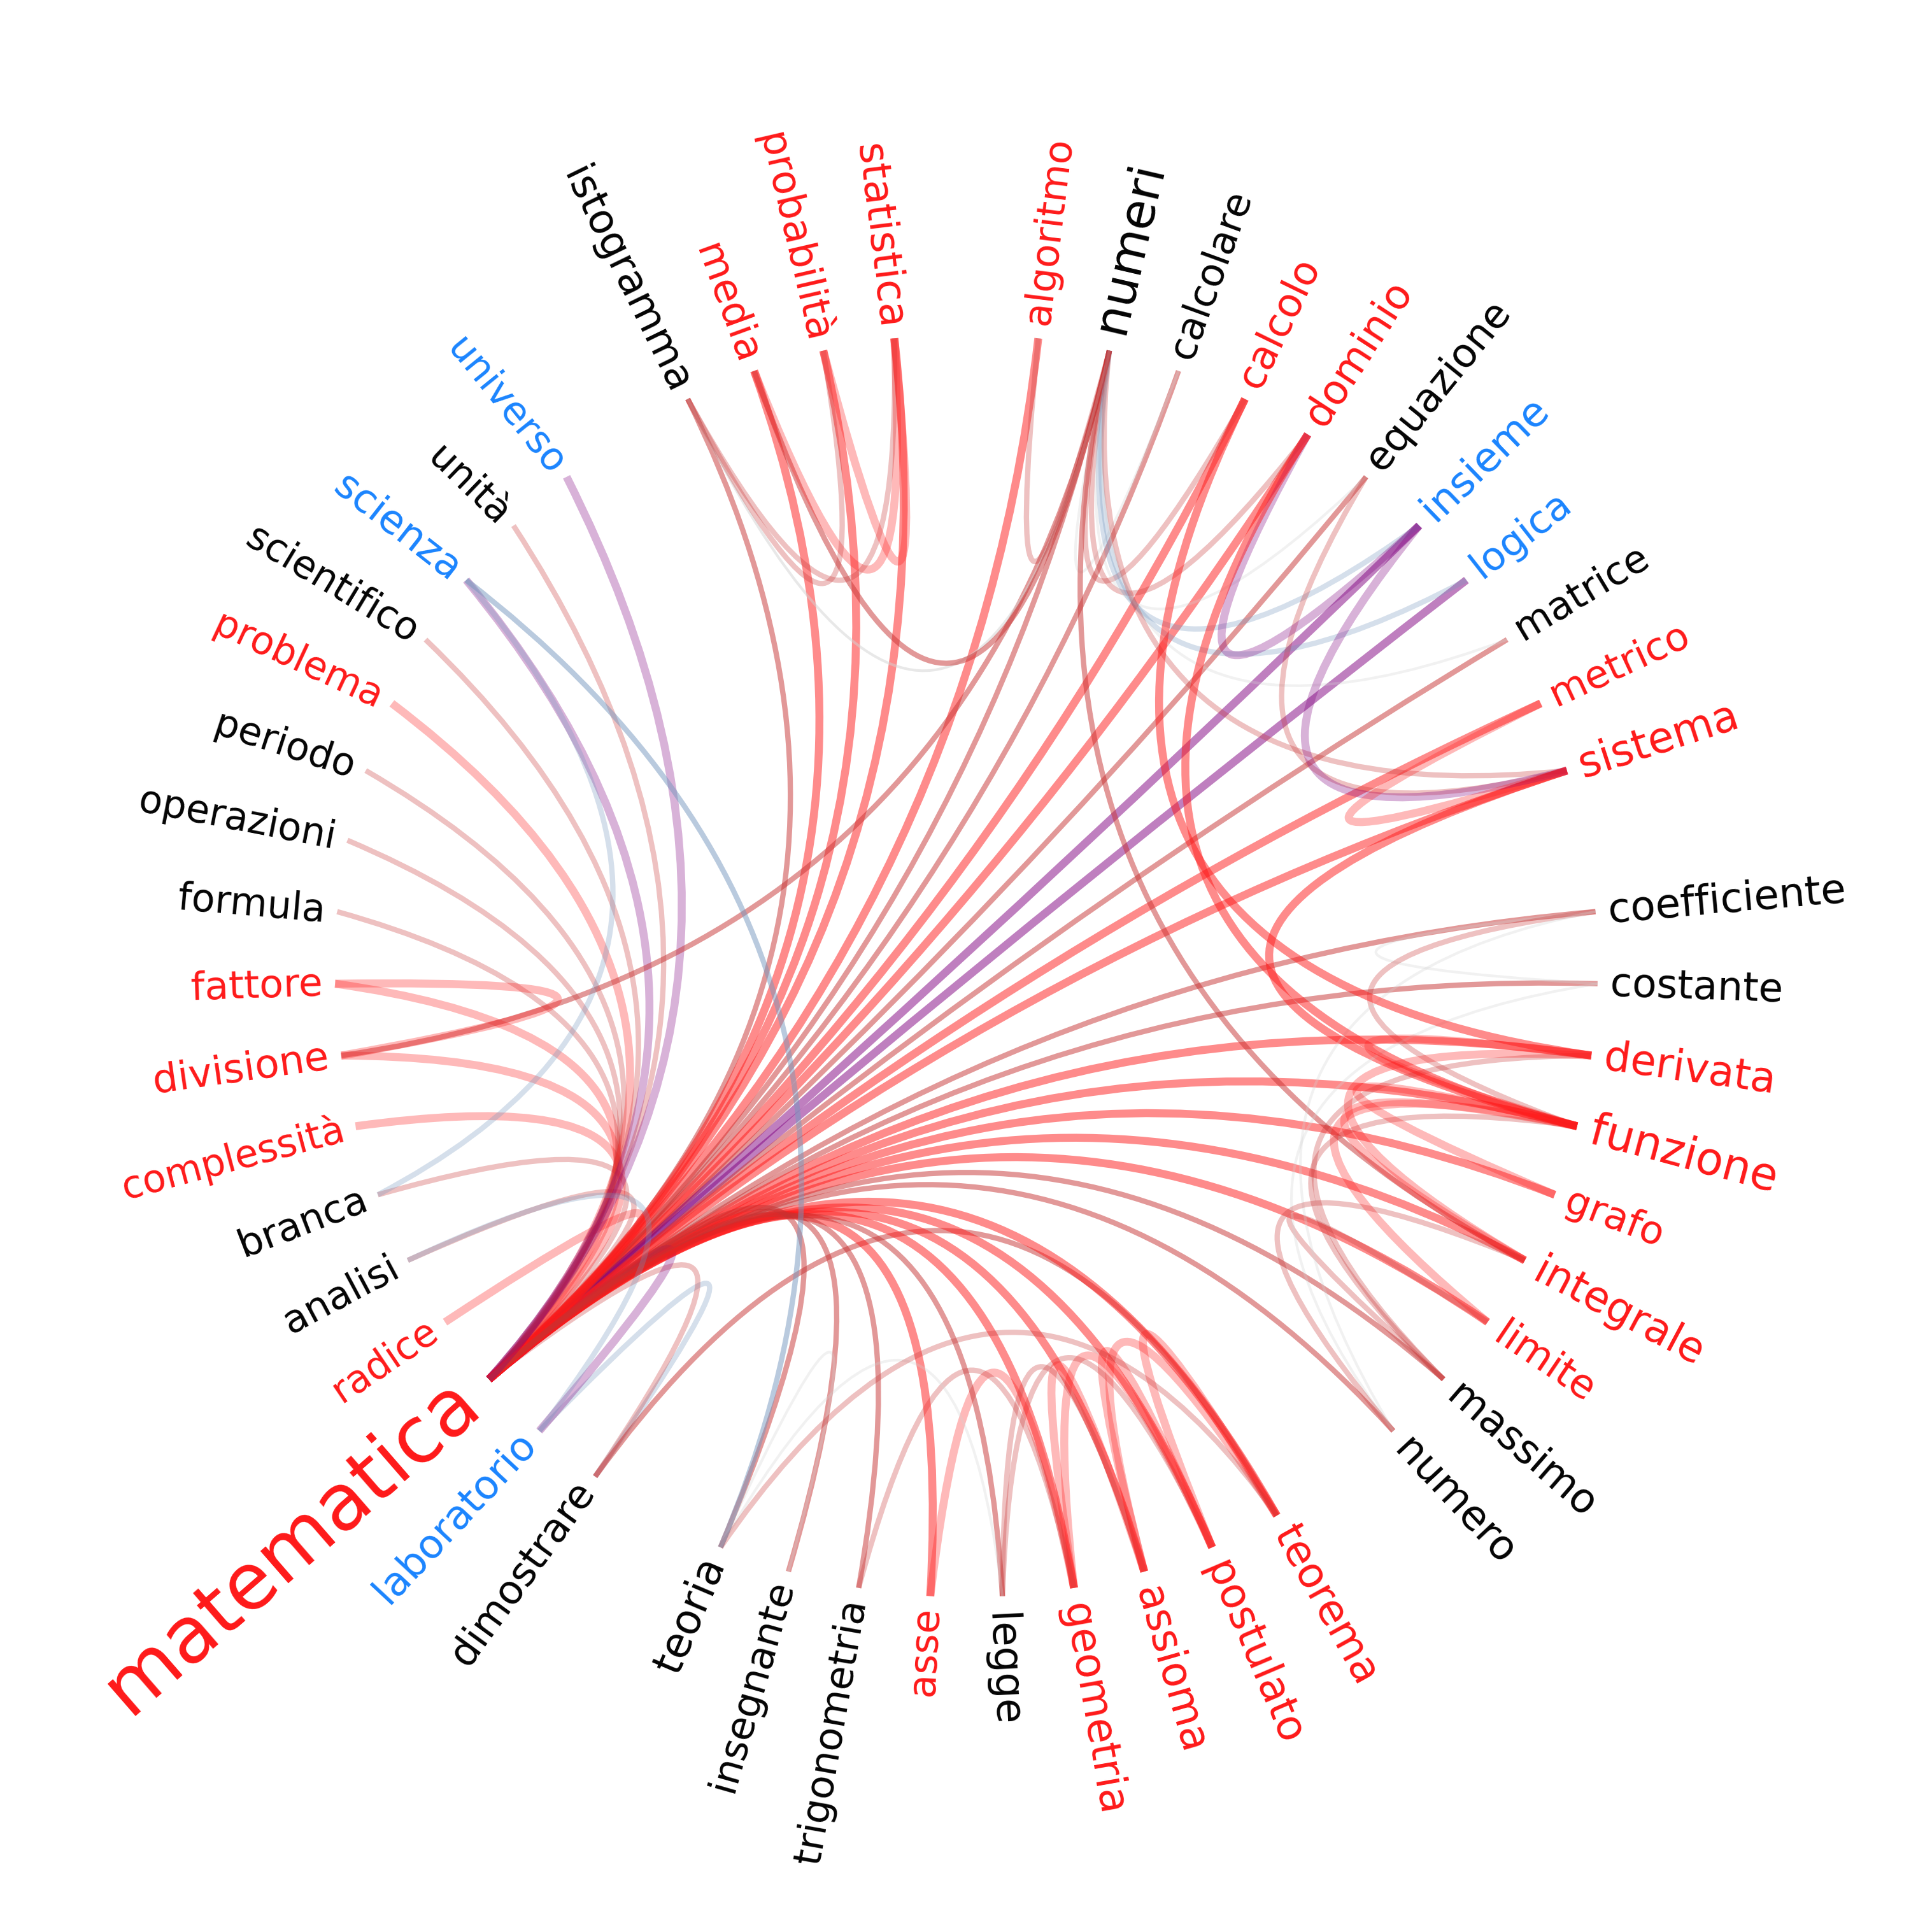

Saved ../out/../out/merged/aggregated/highschool_south_filtered_bfmns/visualizations/highschool_south_filtered_matematica_edge_bundling_semantic_frame.png
Saved ../out/../out/merged/aggregated/highschool_south_filtered_bfmns/visualizations/highschool_south_filtered_matematica_edge_bundling_semantic_frame.svg
Processing 1 emotional flowers in batches of 1

Processing flower batch 1/1
Current memory usage: 4160.05 MB
Error processing flower for highschool_south_filtered_matematica: name 'out_dir' is not defined


KeyboardInterrupt: 

: 

In [ ]:
# Monitor initial memory usage
print("Starting pipeline...\n")

# Import the NetworkX graphs from txt files with custom valences
# Merge multiple edge Students files, filtered + unfiltered edges + student valences:
result = import_fmnt_from_old_text_format(
    files=[
        "../data/students_and_experts_stella_2019/Students_Filtered.txt",
        "../data/students_and_experts_stella_2019/ValenceStudentsUPD.txt"
    ],
    alpha=0.1,
    min_occurrences=3,
    direction_stat="mean",  # as requested
    directed=False
)

G_merged = result["graph"]
edges_df = result["edges"]
valence_df = result["valence_df"]
custom_valences = result["custom_valences"]

# Build the aggregated BFMN from the graph, keeping the custom valences
merged_fmn = emo.nxgraph_to_formamentis(G_merged)

monitor_memory()

# Export FMNs with custom valences
export_whole_fmn_multiple_custom(
    fmnts=[merged_fmn],
    save_path=files_output_dir,
    filename=f'{group_name}',
    custom_valences=custom_valences
)

# Load Brysbaert concreteness dataset
df_brysbaert = pd.read_csv('../data/brysbaert_concreteness_dataset_eng_ita/brysbaert_concreteness_dataset_eng_ita.csv')
# Draw and save semantic frame plots and emo flowers for each keyword
# for each keyword in keywords extract it, then draw the semantic
# frame plot, save it and show it in the notebook
layout = "edge_bundling"
if len(keywords) > 0:
    for keyword in keywords:
        semantic_frame = emo.extract_word_from_formamentis(merged_fmn, keyword)
        if not hasattr(semantic_frame, "vertices") or len(semantic_frame.vertices) == 0:
            print(f"Skipping '{keyword}': not in network or empty semantic frame.")
            continue
        out_dir = f'{base_output_path}/{files_output_dir}/visualizations'
        filename = f'{group_name}_{keyword}_{layout}_semantic_frame'
        draw_fmnts(
            fmnts={group_name: semantic_frame},
            out_dir=out_dir,
            layout=layout,
            highlight=[],
            thickness=1,
            ax=None,
            emo=emo,
            custom_valences=custom_valences,
            filename_base=filename,
        )
        make_emo_flowers(
            fmnts={f'{group_name}_{keyword}': semantic_frame},
            save_path=out_dir,
            filename=f'{group_name}_{keyword}_emo_flower',
            emo=emo,
            batch_size=1
        )


        if use_prelemmatized_brysbaert:
                # Analyze concreteness of the semantic frame (fast, pre-lemmatized datasets)
                try:
                    result = emo.analyze_semantic_frame_concreteness_fast(
                        semantic_frame,
                        seed=None,
                        save_json_path=f'{base_output_path}/{files_output_dir}/analysis/{group_name}_{keyword}_concreteness_analysis.json',
                        save_figure_path=f'{base_output_path}/{files_output_dir}/visualizations/{group_name}_{keyword}_concreteness_analysis.png',
                        plot=True
                    )
                    print(result['p_value'])
                    print(f"Concreteness analysis for '{keyword}' saved successfully.")
                except Exception as e:
                    print(f"Error analyzing concreteness for '{keyword}': {e}")
            
        else:
            # Analyze concreteness of the semantic frame
            try:
                result = emo.analyze_semantic_frame_concreteness(
                    semantic_frame,
                    df_brysbaert,
                    seed=None,
                    save_json_path=f'{base_output_path}/{files_output_dir}/analysis/{group_name}_{keyword}_concreteness_analysis.json',
                    save_figure_path=f'{base_output_path}/{files_output_dir}/visualizations/{group_name}_{keyword}_concreteness_analysis.png',
                    plot=True
                )
                print(result['p_value'])
                print(f"Concreteness analysis for '{keyword}' saved successfully.")
            except Exception as e:
                print(f"Error analyzing concreteness for '{keyword}': {e}")

monitor_memory()

valence_stats = fmn_valence_stats(merged_fmn, custom_valences, emo=emo)
print("Valence stats:", valence_stats)

print(G_merged)
print("Graph:", G_merged.nodes(data=True))
print("Custom valences:", custom_valences)

# Make a dictionary of the merged BFMN for further processing
if merged_fmn is not None:
    bfmns = {fmn_type: merged_fmn}

# Compute node_valence_maps for the merged BFMN
# Collect node valences separately (cannot attach to namedtuple)
node_val_maps = {}
node_val_maps[fmn_type] = {n: d.get("valence_cat") for n, d in G_merged.nodes(data=True)}

'''valence_stats = fmn_valence_stats(merged_fmn, custom_valences, emo=emo)
print("Valence stats:", valence_stats)

# Inspect the merged BFMN
inspect_fmn(
    fmn=merged_fmn,
    participant=group_name,
    all_features={group_name: valence_stats},
    emo=emo
)'''

# Check for presence of each keyword in the fmn
verify_and_report_nodes(
    fmns={group_name: merged_fmn},
    required=keywords
)

# Compute and export structural features for the aggregated FMN
aggregated_features = extract_bfmn_structural_features(
    fmnts={group_name: merged_fmn},
    save_path=f'{base_output_path}/{files_output_dir}/structural_features',
    emo=emo,
    batch_size=1,
    node_valence_maps=node_val_maps,
    persist=True
)

# Convert features to DataFrame and export
aggregated_features_df = all_fmns_features_df(aggregated_features, orient="participants")
export_df(aggregated_features_df, f'{base_output_path}/{files_output_dir}/structural_features', filename=f'{group_name}_structural_features')

### Individual pipeline

In [ ]:
# Method to execute: individual BFMNs per participant
if 'individual' in methods:
    print("Starting individual pipeline...\n")

    # Build BFMNs for each participant
    individual_fmns, node_val_maps = build_participants_bfmns(
        final_df,
        emo=emo,
        directed=False,
        lemmatize=False,
        keep_original_columns=True
    )

    # Now, call the functions with your data.
    print(f"Built {len(individual_fmns)} FMNs for this data")
    monitor_memory()

    # Extract features from BFMNs
    all_features = extract_bfmn_structural_features(
        fmnts=individual_fmns,
        save_path=files_output_dir,
        node_valence_maps=node_val_maps
    )

    # Export BFMNs
    export_whole_fmn_multiple_custom(
        fmnts=individual_fmns,
        save_path=files_output_dir,  # was f'{base_output_path}/{files_output_dir}'
        filename="fmn",
        custom_valences=custom_valences,
        language=language
    )

    # draw_formamentis for each keyword in each participant BFMN
    viz_dir = f'{files_output_dir}/visualizations'  # was f'{base_output_path}/{files_output_dir}/visualizations'
    os.makedirs(viz_dir, exist_ok=True)
    for participant_id, fmnt in individual_fmns.items():
        for keyword in keywords:
            semantic_frame = emo.extract_word_from_formamentis(fmnt, keyword)

            # Skip empty frames to avoid draw errors
            if (semantic_frame is None
                or not hasattr(semantic_frame, "vertices")
                or len(getattr(semantic_frame, "vertices", [])) == 0):
                print(f"Skipping empty semantic frame for '{keyword}' in '{participant_id}'.")
                continue

            fig, ax = plt.subplots(figsize=(10, 10), dpi=300)
            emo.draw_formamentis(
                fmn=semantic_frame,
                layout="edge_bundling",
                highlight=[],
                thickness=1,
                ax=ax,
                save_path=None,
                custom_valences=custom_valences
            )

            print(f"Semantic Frame for '{keyword.title()}' in participant '{participant_id}' BFMN:")
            save_base = os.path.join(viz_dir, f"{participant_id}_{keyword}_edge_bundling_semantic_frame")
            fig.savefig(f"{save_base}.png", dpi=300)
            fig.savefig(f"{save_base}.svg")
            plt.close(fig)

    # Make emotional flowers for BFMNs (skip flowers to save memory - uncomment if needed)
    # For now, we skip it because it has less meaning for BFMNs
    make_emo_flowers(
        fmnts=individual_fmns,
        save_path=os.path.join(viz_dir, "emo_flowers"),
    )

    print("Pipeline completed!")
    monitor_memory()

    # fmn features dataframe (participants as rows, features as columns)
    structural_fmns_features_df = all_fmns_features_df(
        features_dict=all_features,
        orient="participants"
    )

    structural_fmns_features_df.to_csv(f'{base_output_path}/{data_output_dir}/{project_name}_all_bfmns_structural_features.csv')

    '''# Inspect the created fmnts
    for fmn_title, fmn in individual_fmns.items():
        participant = fmn_title
        print(f"\nInspecting FMN for participant: {participant} with {len(fmn.vertices)} vertices")
        # Call the inspect function
        inspect_fmn(
        fmn,
        participant=participant,
        all_features=all_features
    )'''